<a href="https://colab.research.google.com/github/TasminaTasin75/binary-classification-mnist-dataset/blob/main/ml_assignment_build_analyze_binary_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
import os

DATASET_PATH = "/content/drive/MyDrive/Colab Notebooks/ML-Assignment-MNIST/dataset/mnist_1_7_subsets-1.npz"

print("Does Dataset exists? :", os.path.exists(DATASET_PATH))


Does Dataset exists? : True


**Task 1: Data Exploration and Analysis**

In [3]:
# Loading the dataset
import numpy as np

data = np.load(DATASET_PATH)

print(data)

NpzFile '/content/drive/MyDrive/Colab Notebooks/ML-Assignment-MNIST/dataset/mnist_1_7_subsets-1.npz' with keys: train_data, train_targets, test_data, test_targets


In [4]:
#Accessing the available arrays
X_train = data["train_data"]
y_train = data["train_targets"]

X_test = data["test_data"]
y_test = data["test_targets"]

# checking the shapes

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", X_test.shape)
print("Test labels:", y_test.shape)


Training images: (100, 28, 28)
Training labels: (100,)
Test images: (1000, 28, 28)
Test labels: (1000,)


Looking inside the dataset

In [5]:
# Data types
print("Data types:")
print("Training images:", X_train.dtype)
print("Training labels:", y_train.dtype)
print("Test images:", X_test.dtype)
print("Test labels:", y_test.dtype)

Data types:
Training images: uint8
Training labels: int64
Test images: uint8
Test labels: int64


In [6]:
# Labels
print("Training labels:", np.unique(y_train))
print("Test labels:", np.unique(y_test))

Training labels: [1 7]
Test labels: [1 7]


Checking the Class balance to see the number of images of digit 1 and 7 exist in each dataset

In [7]:
train_labels, train_counts = np.unique(
    y_train, return_counts=True
)

test_labels, test_counts = np.unique(
    y_test, return_counts=True
)

print("Training set class distribution:")
for label, count in zip(train_labels, train_counts):
    percentage = count / len(y_train) * 100
    print(f"Digit {label}: {count} images  - {percentage:.2f}%")

print("Test set class distribution:")
for label, count in zip(test_labels, test_counts):
    percentage = count / len(y_test) * 100
    print(f"Digit {label}: {count} images  - {percentage:.2f}%")


Training set class distribution:
Digit 1: 50 images  - 50.00%
Digit 7: 50 images  - 50.00%
Test set class distribution:
Digit 1: 100 images  - 10.00%
Digit 7: 900 images  - 90.00%


**Insight:** The training set is perfectly balanced (50 vs 50), so the classifier will not be biased toward either class during training. The test set is heavily imbalanced e.g 10% 1s, 90% 7s. A model that always predicted "7" would reach 90% accuracy without learning anything. Only accuracy is not enough to describe this case well. Balanced accuracy and macro-F1 are better to be used as the primary metrics.

Check for missing values in train data

In [8]:
missing_val = np.isnan(X_train).sum()
print("Missing values in training images:", missing_val)

Missing values in training images: 0


Pixel Intensity Stats

In [9]:
# Pixel intensity range
print("Training pixel intensity:")
print("Minimum:", X_train.min())
print("Maximum:", X_train.max())
print("Mean:", round(X_train.mean(), 2))
print("Standard deviation:", round(X_train.std(), 2))


print("\nTest pixel intensity:")
print("Minimum:", X_test.min())
print("Maximum:", X_test.max())

Training pixel intensity:
Minimum: 0
Maximum: 255
Mean: 24.85
Standard deviation: 69.69

Test pixel intensity:
Minimum: 0
Maximum: 255


Pixel intensity Stats for each digit

In [10]:
print("Pixel statistics for each digit:")

for digit in [1, 7]:
    digit_images = X_train[y_train == digit]

    print(f"\nDigit {digit}:")
    print("Number of images:", len(digit_images))
    print("Mean pixel intensity:", round(digit_images.mean(), 2))
    print("Pixel intensity standard deviation:", round(digit_images.std(), 2))

Pixel statistics for each digit:

Digit 1:
Number of images: 50
Mean pixel intensity: 20.18
Pixel intensity standard deviation: 63.75

Digit 7:
Number of images: 50
Mean pixel intensity: 29.53
Pixel intensity standard deviation: 74.88


Visualizing the sample images (5 images of Digit 1 and 5 images of digit 7)

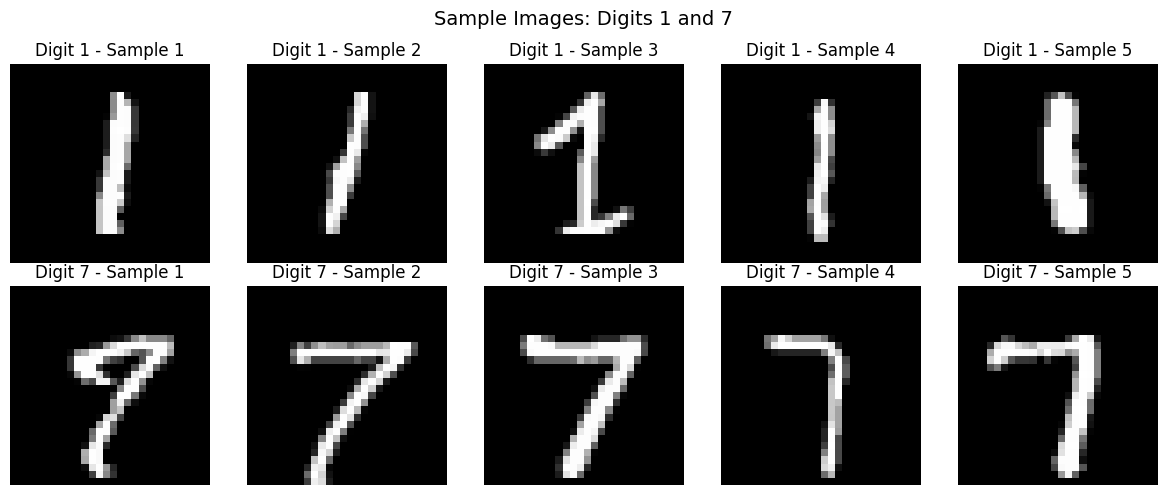

In [11]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

# Displaying 5 samples of each digit
for row, digit in enumerate([1, 7]):
    digit_images = X_train[y_train == digit]

    for col in range(5):
        axes[row, col].imshow(digit_images[col], cmap="gray", vmin=0, vmax=255)
        axes[row, col].set_title(f"Digit {digit} - Sample {col + 1}")
        axes[row, col].axis("off")

plt.suptitle("Sample Images: Digits 1 and 7", fontsize=14)
plt.tight_layout()
plt.show()


Visualizing the average image of digit 1 and 7 by mean intensity of each digit

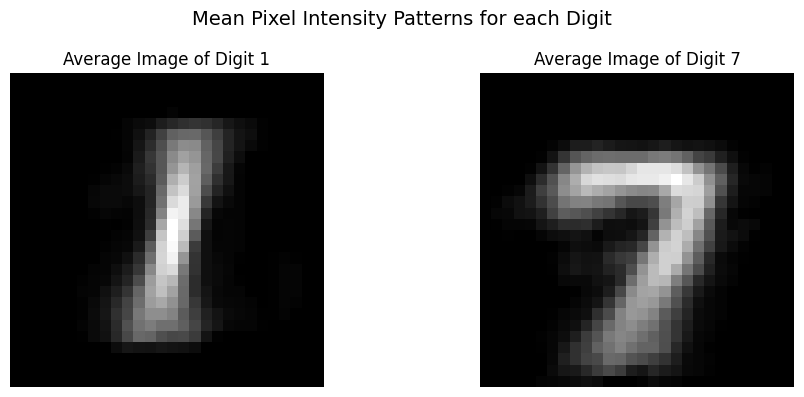

In [12]:

# getting digit 1 training images
digit_1_images = X_train[y_train == 1]
# getting digit 7 training images
digit_7_images = X_train[y_train == 7]

# Calculating the mean intensity
mean_digit_1 = digit_1_images.mean(axis=0)
mean_digit_7 = digit_7_images.mean(axis=0)

# Displaying the two average images
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(mean_digit_1, cmap="gray")
axes[0].set_title("Average Image of Digit 1")
axes[0].axis("off")

axes[1].imshow(mean_digit_7, cmap="gray")
axes[1].set_title("Average Image of Digit 7")
axes[1].axis("off")

plt.suptitle("Mean Pixel Intensity Patterns for each Digit", fontsize=14)
plt.tight_layout()
plt.show()


Difference map of digit 1 and 7

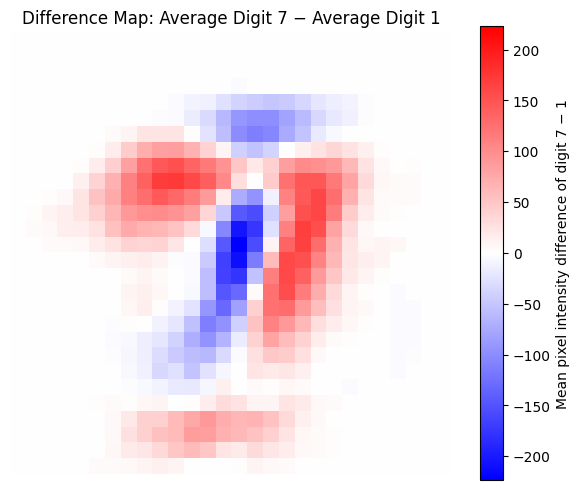

In [13]:
# Difference between the average images of digit 7 and digit 1
diff = mean_digit_7 - mean_digit_1

# Keep the colour scale symmetric around zero
limit = np.abs(diff).max()

plt.figure(figsize=(6, 5))
plt.imshow(
    diff,
    cmap="bwr",
    vmin=-limit,
    vmax=limit
)

plt.colorbar(label="Mean pixel intensity difference of digit 7 − 1")
plt.title("Difference Map: Average Digit 7 − Average Digit 1")
plt.axis("off")
plt.tight_layout()
plt.show()


Comparing the ink usage for Digit 1 and Digit 7

- compares total pixel intensity of individual image from each class using a boxplot

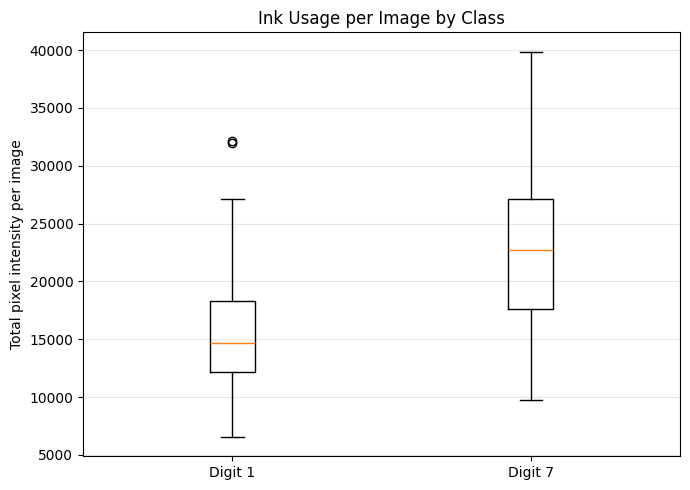

Digit 1: mean intensity total = 15823.0, standard deviation = 5139.9
Digit 7: mean intensity total = 23147.6, standard deviation = 6497.6


In [14]:
# Calculating total pixel intensity for each original training image
ink = X_train.reshape(len(X_train), -1).sum(axis=1)

# Separating the intensity totals of digit 1 and 7
ink_digit_1 = ink[y_train == 1]
ink_digit_7 = ink[y_train == 7]

# Comparing the two classes using a boxplot
plt.figure(figsize=(7, 5))
plt.boxplot(
    [ink_digit_1, ink_digit_7],
    tick_labels=["Digit 1", "Digit 7"]
)

plt.ylabel("Total pixel intensity per image")
plt.title("Ink Usage per Image by Class")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

#  Summary statistics
for digit, values in [(1, ink_digit_1), (7, ink_digit_7)]:
    print(
        f"Digit {digit}: "
        f"mean intensity total = {values.mean():.1f}, "
        f"standard deviation = {values.std():.1f}"
    )


Preprocessing the Training data

In [15]:
# Flattening each 28x28 image into a 784 features as most of the classifiers expect one dimentional feature vector rather than 2 dimentional images
X_train_flattened = X_train.reshape(X_train.shape[0], -1)
X_test_flattened = X_test.reshape(X_test.shape[0], -1)

# Converting pixel values to floating-point numbers and normalize the pixel intesities to 0-1
X_train_scaled = X_train_flattened.astype(np.float32) / 255.0
X_test_scaled = X_test_flattened.astype(np.float32) / 255.0

# Preprocessing results
print("Training data shape:", X_train_scaled.shape)
print("Test data shape:", X_test_scaled.shape)

print("\nTraining pixel range:",
      X_train_scaled.min(), "-", X_train_scaled.max())
print("Test pixel range:",
      X_test_scaled.min(), "-", X_test_scaled.max())


Training data shape: (100, 784)
Test data shape: (1000, 784)

Training pixel range: 0.0 - 1.0
Test pixel range: 0.0 - 1.0


**Insight:** here in this preprocessing step, we flatten the 28x28 two dimentional images into one dimentional 784 feature vector as most of the traditional classifers expect this instead of two dimentional image. Then we normalize the pixel intensities in the range of 0 to 1 so that the features can share a common scale. Moreover, we keep the train and test set separate to prevent data leakage.

Checking the Prepared Data

- check if feature rows equal to training labels
- both digit present in the trainig set
- does not include any invalid value

In [16]:
# Verifying the prepared training data and labels
print("Training features:", X_train_scaled.shape)
print("Training labels:", y_train.shape)

print("\nLabels present:", np.unique(y_train))
print("Training samples per class:")

for digit in [1, 7]:
    print(f"Digit {digit}: {np.sum(y_train == digit)} samples")

# Check for invalid values after normalization
print("\nNaN values:", np.isnan(X_train_scaled).sum())
print("Infinite values:", np.isinf(X_train_scaled).sum())


Training features: (100, 784)
Training labels: (100,)

Labels present: [1 7]
Training samples per class:
Digit 1: 50 samples
Digit 7: 50 samples

NaN values: 0
Infinite values: 0


**Task 2: Build a Classification System**

Baseline Evaluation of Logistic Regression

In [17]:
# Logistic Regression baseline with repeated cross-validation

import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

# Repeated stratified 5-fold cross-validation: 5 folds x 10 repeats
cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)


lr_model = LogisticRegression(
    C=1.0,
    max_iter=2000,
    random_state=42
)


def evaluate_cv(model, X, y, cv):
    scoring = {
        "accuracy": "accuracy",
        "macro_f1": "f1_macro",
        "balanced_accuracy": "balanced_accuracy",
        "roc_auc": "roc_auc"
    }

    results = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1
    )

    print(f"Cross-validation results ({cv.get_n_splits()} validation folds)")
    print("-" * 55)

    for metric in scoring:
        train_scores = results[f"train_{metric}"]
        val_scores = results[f"test_{metric}"]

        print(f"\n{metric}:")
        print(f"  Training mean:   {train_scores.mean():.4f}")
        print(f"  Validation mean: {val_scores.mean():.4f}")
        print(f"  Validation std:  {val_scores.std():.4f}")
        print(f"  Train - CV gap:  "
              f"{train_scores.mean() - val_scores.mean():.4f}")

    return results

# Evaluate using training data
lr_cv_results = evaluate_cv(
    lr_model,
    X_train_scaled,
    y_train,
    cv
)

# Fit the final baseline model on all training data
lr_model.fit(X_train_scaled, y_train)

print("\nBaseline Logistic Regression fitted on all training data.")


Cross-validation results (50 validation folds)
-------------------------------------------------------

accuracy:
  Training mean:   1.0000
  Validation mean: 0.9930
  Validation std:  0.0200
  Train - CV gap:  0.0070

macro_f1:
  Training mean:   1.0000
  Validation mean: 0.9930
  Validation std:  0.0201
  Train - CV gap:  0.0070

balanced_accuracy:
  Training mean:   1.0000
  Validation mean: 0.9930
  Validation std:  0.0200
  Train - CV gap:  0.0070

roc_auc:
  Training mean:   1.0000
  Validation mean: 0.9996
  Validation std:  0.0020
  Train - CV gap:  0.0004

Baseline Logistic Regression fitted on all training data.


Confusion matrix

Confusion Matrix
[[49  1]
 [ 0 50]]


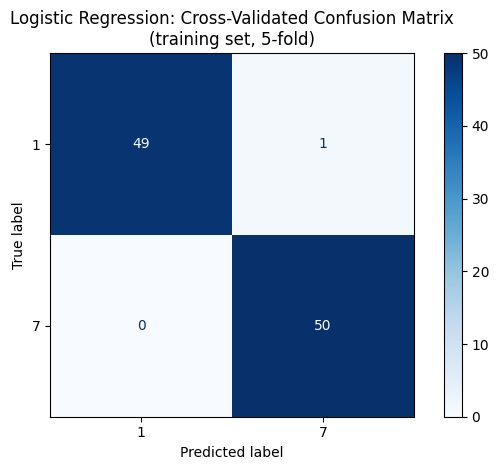

In [18]:
# Confusion matrix using cross-validated predictions
# cross_val_predict requires each sample to be predicted exactly once,
# so a single (non-repeated) stratified 5-fold split is used here.

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cv_single = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Each training image is predicted by a model that did not see it
y_train_pred = cross_val_predict(
    lr_model,
    X_train_scaled,
    y_train,
    cv=cv_single,
    method="predict",
    n_jobs=-1
)

# Calculate the confusion matrix
confusionMatrix = confusion_matrix(y_train, y_train_pred, labels=[1, 7])

print("Confusion Matrix")
print(confusionMatrix)

# Visualise the confusion matrix
cm_display = ConfusionMatrixDisplay(
    confusion_matrix=confusionMatrix,
    display_labels=[1, 7]
)
cm_display.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression: Cross-Validated Confusion Matrix\n(training set, 5-fold)")
plt.tight_layout()
plt.show()

**Insight:** Across 5-fold cross-validated predictions, the model correctly classified 99 of 100 training images. The only error was a digit 1 predicted as a 7; no 7s were misclassified. This suggests the model's errors occur on unusual 1s. This may happen with 1s that are slanted or have a small hook at the top, which can look like the top line of a 7. The test set has very few 1s (only 10%). So even a few mistakes on 1s would lower macro-F1 and balanced accuracy noticeably, while plain accuracy would hardly change. This is why we use metrics that treat both digits equally.

Comparing Logistic Regression Weights with the Difference Map in Task 1

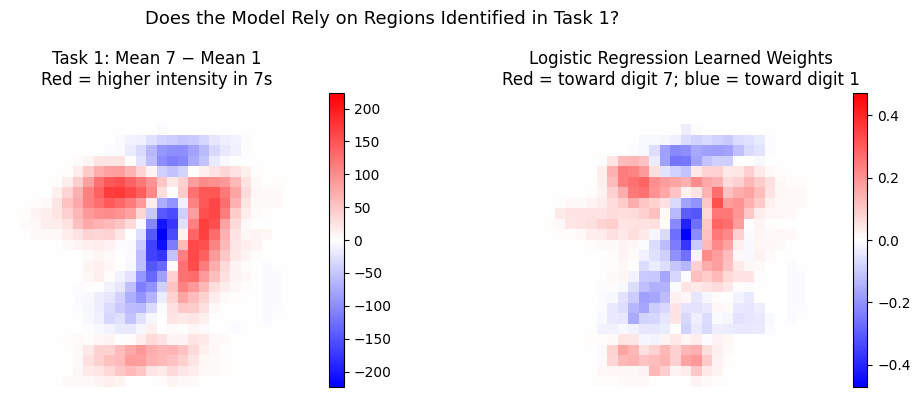

In [19]:

# Comparing the learned weights with the Task 1 difference map

weights = lr_model.coef_.reshape(28, 28)

# Mean image difference: digit 7 minus digit 1
diff = mean_digit_7 - mean_digit_1

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

im0 = axes[0].imshow(
    diff,
    cmap="bwr",
    vmin=-np.abs(diff).max(),
    vmax=np.abs(diff).max()
)
axes[0].set_title("Task 1: Mean 7 − Mean 1\nRed = higher intensity in 7s")
axes[0].axis("off")
plt.colorbar(im0, ax=axes[0], fraction=0.046)

lim = np.abs(weights).max()
im1 = axes[1].imshow(
    weights,
    cmap="bwr",
    vmin=-lim,
    vmax=lim
)
axes[1].set_title("Logistic Regression Learned Weights\nRed = toward digit 7; blue = toward digit 1")
axes[1].axis("off")
plt.colorbar(im1, ax=axes[1], fraction=0.046)

plt.suptitle(
    "Does the Model Rely on Regions Identified in Task 1?",
    fontsize=13
)
plt.tight_layout()
plt.show()


**Insight**: The comparison shows how Logistic Regression's learned pixel weights relate to the average intensity differences between digits 1 and 7. Similar colour patterns suggest that the model uses pixel regions that help distinguish the two digits. But, the maps may not match exactly because the difference map compares average images, while Logistic Regression learns weights jointly across all pixels to make classification decisions.

**Task 3: Comparison of Two Classifiers & Hyperparameter Tuning**

Tuning Logistic Regression hyperparameters with GridSearch

Hyperparameter tuning results:


,C,Penalty,Train Macro-F1,Train Macro-F1 Std,Validation Macro-F1,Validation Macro-F1 Std,Validation Accuracy,Validation Balanced Accuracy,Validation ROC-AUC
0,0.0001,l1,0.3333,0.0000,0.3333,0.0000,0.500,0.500,0.5000
1,0.0003,l1,0.3333,0.0000,0.3333,0.0000,0.500,0.500,0.5000
2,0.0010,l1,0.3333,0.0000,0.3333,0.0000,0.500,0.500,0.5000
3,0.0032,l1,0.3333,0.0000,0.3333,0.0000,0.500,0.500,0.5000
4,0.0100,l1,0.3333,0.0000,0.3333,0.0000,0.500,0.500,0.5000
5,0.0316,l1,0.3333,0.0000,0.3333,0.0000,0.500,0.500,0.5000
6,0.1000,l1,0.9622,0.0187,0.9280,0.0635,0.929,0.929,0.9910
7,0.3162,l1,0.9865,0.0074,0.9669,0.0370,0.967,0.967,0.9958
8,1.0000,l1,0.9995,0.0024,0.9649,0.0351,0.965,0.965,0.9952
9,3.1623,l1,1.0000,0.0000,0.9588,0.0372,0.959,0.959,0.9956



Selected hyperparameters:
C: 1000.0
Penalty: l2
Validation Macro-F1: 0.996
Selection rule: highest mean validation Macro-F1;
if within 0.001 of the best, prefer the smallest C.


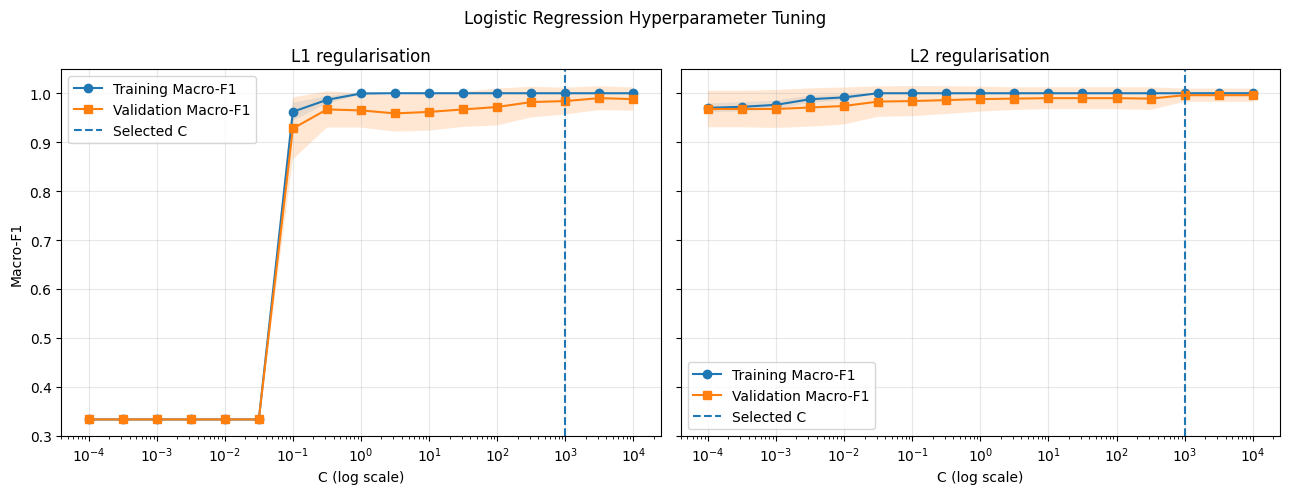


Tuned Logistic Regression fitted on all training samples.


In [20]:

# Tuning Logistic Regression hyperparameters

import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from IPython.display import display as show_table

# Test 17 values of C from 10^-4 to 10^4
C_values = np.logspace(-4, 4, 17)

# Compare L1 and L2 regularisation
param_grid = {
    "C": C_values,
    "penalty": ["l1", "l2"]
}

scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro",
    "balanced_accuracy": "balanced_accuracy",
    "roc_auc": "roc_auc"
}

lr_grid_search = GridSearchCV(
    estimator=LogisticRegression(
        solver="liblinear",
        max_iter=2000,
        random_state=42
    ),
    param_grid=param_grid,
    scoring=scoring,
    refit="macro_f1",
    cv=cv,
    return_train_score=True,
    n_jobs=-1
)

# Tune using training data only
lr_grid_search.fit(X_train_scaled, y_train)

# Collect results
cv_results = lr_grid_search.cv_results_

lr_tuning_df = pd.DataFrame({
    "C": cv_results["param_C"].astype(float),
    "Penalty": cv_results["param_penalty"],
    "Train Macro-F1": cv_results["mean_train_macro_f1"],
    "Train Macro-F1 Std": cv_results["std_train_macro_f1"],
    "Validation Macro-F1": cv_results["mean_test_macro_f1"],
    "Validation Macro-F1 Std": cv_results["std_test_macro_f1"],
    "Validation Accuracy": cv_results["mean_test_accuracy"],
    "Validation Balanced Accuracy": cv_results["mean_test_balanced_accuracy"],
    "Validation ROC-AUC": cv_results["mean_test_roc_auc"]
})

lr_tuning_df = lr_tuning_df.sort_values(
    ["Penalty", "C"]
).reset_index(drop=True)

print("Hyperparameter tuning results:")
show_table(lr_tuning_df.round(4))

# Select the best mean validation Macro-F1.
# If scores are within 0.001 of the best, prefer the smallest C.
best_score = lr_tuning_df["Validation Macro-F1"].max()

near_best = lr_tuning_df[
    lr_tuning_df["Validation Macro-F1"] >= best_score - 0.001
]

chosen = near_best.sort_values(
    ["C", "Penalty"]
).iloc[0]

best_C = float(chosen["C"])
best_penalty = chosen["Penalty"]

print("\nSelected hyperparameters:")
print("C:", best_C)
print("Penalty:", best_penalty)
print("Validation Macro-F1:", round(chosen["Validation Macro-F1"], 4))
print("Selection rule: highest mean validation Macro-F1;")
print("if within 0.001 of the best, prefer the smallest C.")

# Plot training and validation curves with standard deviation bands
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for ax, penalty in zip(axes, ["l1", "l2"]):
    subset = lr_tuning_df[
        lr_tuning_df["Penalty"] == penalty
    ].sort_values("C")

    C = subset["C"].to_numpy()

    train_mean = subset["Train Macro-F1"].to_numpy()
    train_std = subset["Train Macro-F1 Std"].to_numpy()

    val_mean = subset["Validation Macro-F1"].to_numpy()
    val_std = subset["Validation Macro-F1 Std"].to_numpy()

    ax.plot(C, train_mean, marker="o", label="Training Macro-F1")
    ax.fill_between(
        C, train_mean - train_std, train_mean + train_std, alpha=0.12
    )

    ax.plot(C, val_mean, marker="s", label="Validation Macro-F1")
    ax.fill_between(
        C, val_mean - val_std, val_mean + val_std, alpha=0.18
    )

    ax.axvline(best_C, linestyle="--", label="Selected C")
    ax.set_xscale("log")
    ax.set_xlabel("C (log scale)")
    ax.set_title(f"{penalty.upper()} regularisation")
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[0].set_ylabel("Macro-F1")
fig.suptitle("Logistic Regression Hyperparameter Tuning")
plt.tight_layout()
plt.show()

# Fit a separate tuned model on all training samples
lr_tuned_model = LogisticRegression(
    C=best_C,
    penalty=best_penalty,
    solver="liblinear",
    max_iter=2000,
    random_state=42
)

lr_tuned_model.fit(X_train_scaled, y_train)

print("\nTuned Logistic Regression fitted on all training samples.")


**Insight:** L2 regularisation with \(C=1000\) achieved the highest validation Macro-F1 of 99.6%. The small gap between training and validation scores suggests strong performance, although results should be interpreted cautiously given the small training dataset.

Second Classifier: Building the RBF Kernel SVM (non-linear) baseline

In [21]:
# Building and evaluate the baseline RBF Kernel SVM

from sklearn.svm import SVC

# Build the baseline RBF SVM with default hyperparameters
svm_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    probability=False,
    random_state=42
)

# Evaluate using the same repeated stratified cross-validation and the same metrics used for Logistic Regression
svm_cv_results = evaluate_cv(
    svm_model,
    X_train_scaled,
    y_train,
    cv
)

# Fit the baseline model on all training samples
svm_model.fit(X_train_scaled, y_train)

print("\nBaseline RBF SVM fitted on all training data.")
print("Kernel:", svm_model.kernel)
print("C:", svm_model.C)
print("Gamma:", svm_model.gamma)
print("Training samples:", X_train_scaled.shape[0])

# Actual numeric value used by gamma="scale"
gamma_scale = 1 / (X_train_scaled.shape[1] * X_train_scaled.var())
print(f"Gamma ('scale') = {gamma_scale:.5f}")

# Number of support vectors for each class (1, 7)
print("Support vectors per class:", svm_model.n_support_)

Cross-validation results (50 validation folds)
-------------------------------------------------------

accuracy:
  Training mean:   1.0000
  Validation mean: 0.9810
  Validation std:  0.0330
  Train - CV gap:  0.0190

macro_f1:
  Training mean:   1.0000
  Validation mean: 0.9809
  Validation std:  0.0332
  Train - CV gap:  0.0191

balanced_accuracy:
  Training mean:   1.0000
  Validation mean: 0.9810
  Validation std:  0.0330
  Train - CV gap:  0.0190

roc_auc:
  Training mean:   1.0000
  Validation mean: 0.9994
  Validation std:  0.0024
  Train - CV gap:  0.0006

Baseline RBF SVM fitted on all training data.
Kernel: rbf
C: 1.0
Gamma: scale
Training samples: 100
Gamma ('scale') = 0.01708
Support vectors per class: [19 30]


Baseline RBF SVM: The RBF Kernel SVM achieved a mean validation Macro-F1 of 98.09% and a ROC-AUC of 99.94% using repeated stratified 5-fold cross-validation with 10 repeats. Although its training scores were perfect, the training–validation Macro-F1 gap was approximately 1.91 percentage points, indicating some overfitting. The results demonstrate strong baseline classification performance, but hyperparameter tuning is needed to determine whether generalisation can be improved.

RBF SVM hyperparameter tuning

In [22]:
# Hyperparameter tuning with Grid search for RBF SVM (C x gamma)

# Hyperparameter search space
svm_param_grid = {
    "C": np.logspace(-2, 4, 13),
    "gamma": np.logspace(-5, 1, 13)
}

# Defining evaluation metrics
svm_scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro",
    "balanced_accuracy": "balanced_accuracy",
    "roc_auc": "roc_auc"
}

# Configuring GridSearchCV
svm_grid_search = GridSearchCV(
    estimator=SVC(kernel="rbf"),
    param_grid=svm_param_grid,
    scoring=svm_scoring,
    refit="macro_f1",
    cv=cv,
    return_train_score=True,
    n_jobs=-1
)

# Tuning with training data only
svm_grid_search.fit(X_train_scaled, y_train)

# Collecting cross-validation results
svm_cv_results = svm_grid_search.cv_results_

svm_tuning_df = pd.DataFrame({
    "C": np.asarray(svm_cv_results["param_C"], dtype=float),
    "Gamma": np.asarray(svm_cv_results["param_gamma"], dtype=float),
    "Train Macro-F1": svm_cv_results["mean_train_macro_f1"],
    "Train Macro-F1 Std": svm_cv_results["std_train_macro_f1"],
    "Validation Macro-F1": svm_cv_results["mean_test_macro_f1"],
    "Validation Macro-F1 Std": svm_cv_results["std_test_macro_f1"],
    "Validation Accuracy": svm_cv_results["mean_test_accuracy"],
    "Validation Balanced Accuracy": svm_cv_results["mean_test_balanced_accuracy"],
    "Validation ROC-AUC": svm_cv_results["mean_test_roc_auc"]
})

# Display the top 10 configurations
print("Top 10 RBF SVM configurations:")

show_table(
    svm_tuning_df.sort_values(
        "Validation Macro-F1",
        ascending=False
    ).head(10).round(4)
)

# Apply the one-standard-error selection rule
best_svm_row = svm_tuning_df.loc[
    svm_tuning_df["Validation Macro-F1"].idxmax()
]

best_svm_score = best_svm_row["Validation Macro-F1"]

# Approximate standard error across the 50 CV evaluations
svm_standard_error = (
    best_svm_row["Validation Macro-F1 Std"]
    / np.sqrt(cv.get_n_splits())
)

# Retain configurations within one standard error of the best score
svm_near_best = svm_tuning_df[
    svm_tuning_df["Validation Macro-F1"]
    >= best_svm_score - svm_standard_error
]

# Prefer the smallest gamma, followed by the smallest C
svm_selected_row = svm_near_best.sort_values(
    ["Gamma", "C"]
).iloc[0]

best_svm_C = float(svm_selected_row["C"])
best_svm_gamma = float(svm_selected_row["Gamma"])

# Report the selected configuration
print("\nOne-standard-error selection rule")
print("-" * 45)

print(f"Highest validation Macro-F1: {best_svm_score:.4f}")
print(f"Approximate standard error: {svm_standard_error:.5f}")
print(
    f"Selection threshold: "
    f"{best_svm_score - svm_standard_error:.4f}"
)
print(f"Configurations within threshold: {len(svm_near_best)}")

print(f"\nSelected C: {best_svm_C:g}")
print(f"Selected gamma: {best_svm_gamma:g}")

print(
    f"Selected validation Macro-F1: "
    f"{svm_selected_row['Validation Macro-F1']:.4f}"
)

print(
    f"Selected validation Macro-F1 Std: "
    f"{svm_selected_row['Validation Macro-F1 Std']:.4f}"
)

# Show baseline gamma for comparison
print(
    f"\nBaseline gamma ('scale'): {svm_model._gamma:.5f}"
)


Top 10 RBF SVM configurations:


,C,Gamma,Train Macro-F1,Train Macro-F1 Std,Validation Macro-F1,Validation Macro-F1 Std,Validation Accuracy,Validation Balanced Accuracy,Validation ROC-AUC
83,10.0000,0.0032,1.0,0.0,0.997,0.0119,0.997,0.997,0.9998
161,10000.0000,0.0032,1.0,0.0,0.996,0.0136,0.996,0.996,0.9998
109,100.0000,0.0032,1.0,0.0,0.996,0.0136,0.996,0.996,0.9998
135,1000.0000,0.0032,1.0,0.0,0.996,0.0136,0.996,0.996,0.9998
148,3162.2777,0.0032,1.0,0.0,0.996,0.0136,0.996,0.996,0.9998
96,31.6228,0.0032,1.0,0.0,0.996,0.0136,0.996,0.996,0.9998
122,316.2278,0.0032,1.0,0.0,0.996,0.0136,0.996,0.996,0.9998
82,10.0000,0.0010,1.0,0.0,0.995,0.0150,0.995,0.995,1.0000
159,10000.0000,0.0003,1.0,0.0,0.995,0.0150,0.995,0.995,1.0000
144,3162.2777,0.0000,1.0,0.0,0.995,0.0150,0.995,0.995,1.0000



One-standard-error selection rule
---------------------------------------------
Highest validation Macro-F1: 0.9970
Approximate standard error: 0.00168
Selection threshold: 0.9953
Configurations within threshold: 7

Selected C: 10
Selected gamma: 0.00316228
Selected validation Macro-F1: 0.9970
Selected validation Macro-F1 Std: 0.0119

Baseline gamma ('scale'): 0.01708


Final Tuned RBF SVM Model

In [27]:
# Final tuned RBF SVM using the selected hyperparameters
svm_tuned_model = SVC(kernel="rbf", C=best_svm_C, gamma=best_svm_gamma)
svm_tuned_model.fit(X_train_scaled, y_train)
print("Support vectors per class:", svm_tuned_model.n_support_)

Support vectors per class: [15 12]


Visualising tuning results

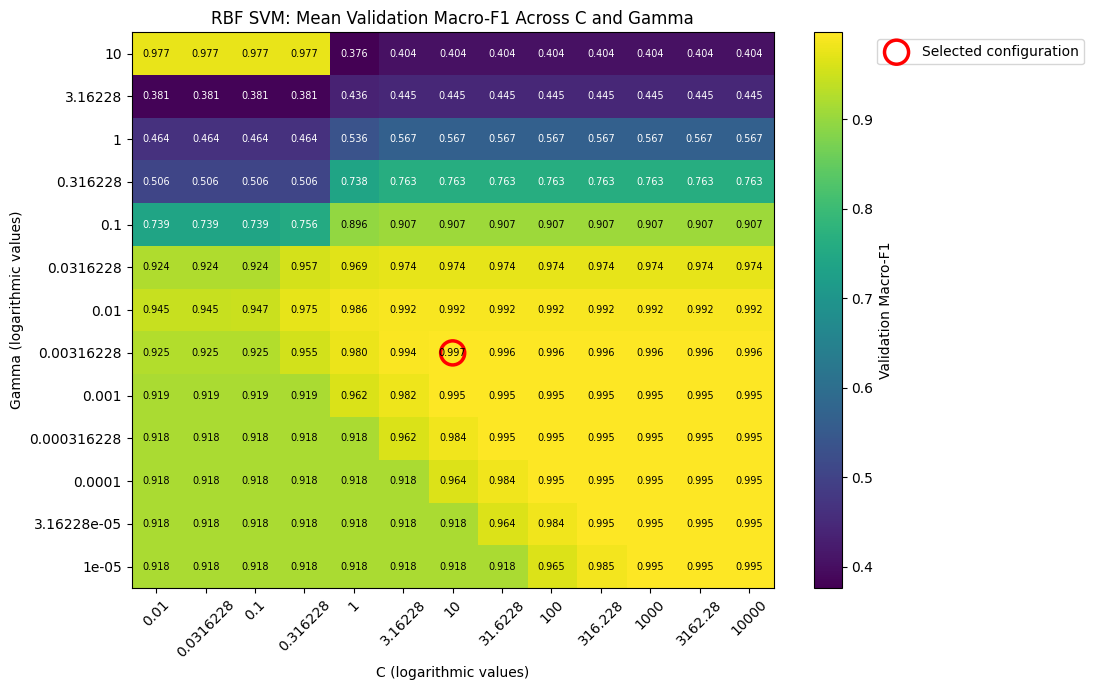

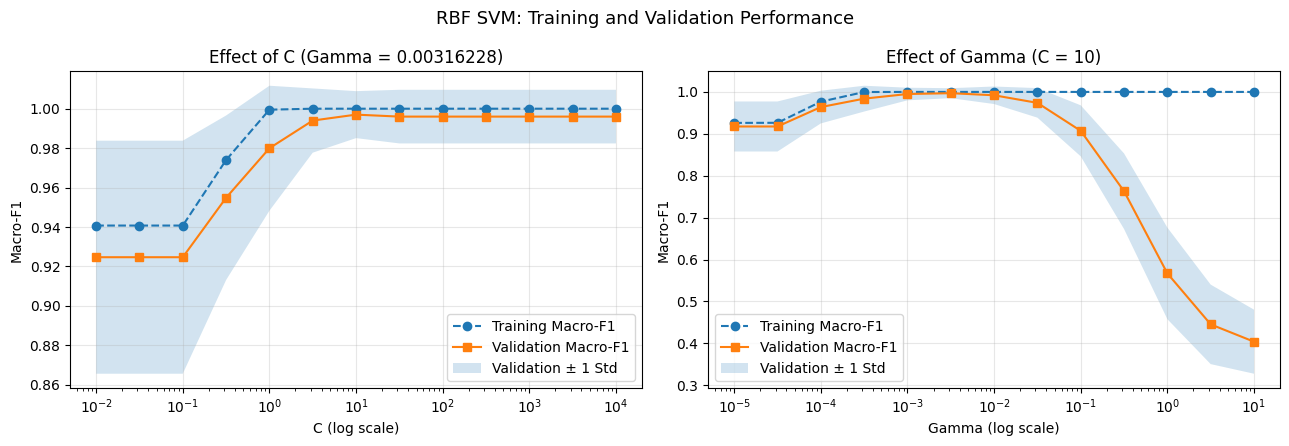

In [26]:

# Heatmap and validation curves

# 1. Create the validation Macro-F1 heatmap
svm_heatmap = svm_tuning_df.pivot(
    index="Gamma",
    columns="C",
    values="Validation Macro-F1"
).sort_index().sort_index(axis=1)

fig, ax = plt.subplots(figsize=(11, 7))

heatmap_image = ax.imshow(
    svm_heatmap.values,
    cmap="viridis",
    origin="lower",
    aspect="auto"
)

# Set axis labels
ax.set_xticks(range(len(svm_heatmap.columns)))
ax.set_xticklabels(
    [f"{c:g}" for c in svm_heatmap.columns],
    rotation=45
)

ax.set_yticks(range(len(svm_heatmap.index)))
ax.set_yticklabels(
    [f"{g:g}" for g in svm_heatmap.index]
)

# Display numerical Macro-F1 values in each cell
for row in range(svm_heatmap.shape[0]):
    for col in range(svm_heatmap.shape[1]):
        score = svm_heatmap.iloc[row, col]

        ax.text(
            col,
            row,
            f"{score:.3f}",
            ha="center",
            va="center",
            fontsize=7,
            color="white" if score < 0.8 else "black"
        )

# Mark the selected hyperparameter combination
selected_col = list(svm_heatmap.columns).index(best_svm_C)
selected_row = list(svm_heatmap.index).index(best_svm_gamma)

ax.scatter(
    selected_col,
    selected_row,
    s=300,
    facecolors="none",
    edgecolors="red",
    linewidths=2.5,
    label="Selected configuration"
)

ax.set_xlabel("C (logarithmic values)")
ax.set_ylabel("Gamma (logarithmic values)")
ax.set_title("RBF SVM: Mean Validation Macro-F1 Across C and Gamma")

plt.colorbar(
    heatmap_image,
    ax=ax,
    label="Validation Macro-F1"
)

ax.legend(loc="upper left", bbox_to_anchor=(1.15, 1.0))
plt.tight_layout()
plt.show()


# 2. Plot training versus validation curves
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Curve A: Vary C while keeping gamma fixed
svm_C_curve = svm_tuning_df[
    np.isclose(svm_tuning_df["Gamma"], best_svm_gamma)
].sort_values("C")

axes[0].plot(
    svm_C_curve["C"],
    svm_C_curve["Train Macro-F1"],
    "o--",
    label="Training Macro-F1"
)

axes[0].plot(
    svm_C_curve["C"],
    svm_C_curve["Validation Macro-F1"],
    "s-",
    label="Validation Macro-F1"
)

axes[0].fill_between(
    svm_C_curve["C"],
    svm_C_curve["Validation Macro-F1"]
    - svm_C_curve["Validation Macro-F1 Std"],
    svm_C_curve["Validation Macro-F1"]
    + svm_C_curve["Validation Macro-F1 Std"],
    alpha=0.2,
    label="Validation ± 1 Std"
)

axes[0].set_xscale("log")
axes[0].set_xlabel("C (log scale)")
axes[0].set_ylabel("Macro-F1")
axes[0].set_title(
    f"Effect of C (Gamma = {best_svm_gamma:g})"
)
axes[0].grid(alpha=0.3)
axes[0].legend()


# Curve B: Vary gamma while keeping C fixed
svm_gamma_curve = svm_tuning_df[
    np.isclose(svm_tuning_df["C"], best_svm_C)
].sort_values("Gamma")

axes[1].plot(
    svm_gamma_curve["Gamma"],
    svm_gamma_curve["Train Macro-F1"],
    "o--",
    label="Training Macro-F1"
)

axes[1].plot(
    svm_gamma_curve["Gamma"],
    svm_gamma_curve["Validation Macro-F1"],
    "s-",
    label="Validation Macro-F1"
)

axes[1].fill_between(
    svm_gamma_curve["Gamma"],
    svm_gamma_curve["Validation Macro-F1"]
    - svm_gamma_curve["Validation Macro-F1 Std"],
    svm_gamma_curve["Validation Macro-F1"]
    + svm_gamma_curve["Validation Macro-F1 Std"],
    alpha=0.2,
    label="Validation ± 1 Std"
)

axes[1].set_xscale("log")
axes[1].set_xlabel("Gamma (log scale)")
axes[1].set_ylabel("Macro-F1")
axes[1].set_title(
    f"Effect of Gamma (C = {best_svm_C:g})"
)
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.suptitle(
    "RBF SVM: Training and Validation Performance",
    fontsize=13
)

plt.tight_layout()
plt.show()


RBF SVM Hyperparameter Tuning: The RBF Kernel SVM was tuned using a grid search of 169 combinations of C and gamma, evaluated through repeated stratified 5-fold cross-validation with 10 repeats. The highest mean validation Macro-F1 was 99.70%, achieved with C = 10 and gamma = 0.003162. The one-standard-error selection rule selected this configuration because it achieved the highest validation score while satisfying the preference for smaller gamma and C values. Its validation standard deviation was 1.19 percentage points, while its training Macro-F1 was 100%. These results demonstrate strong classification performance, although the small training dataset means that the results should be interpreted cautiously.

Comparison of the Tuned Models (Cross-Validation)

Tuned Classifier Comparison
Repeated Stratified 5-Fold CV × 10 Repeats
Training data only (50 validation folds)



,Validation Accuracy,Validation Macro-F1,Balanced Accuracy,ROC-AUC,Train-CV Gap (Macro-F1),Mean Fit Time (seconds),Model Complexity
Model,,,,,,,
Logistic Regression,0.9960 ± 0.0136,0.9960 ± 0.0136,0.9960 ± 0.0136,0.9996 ± 0.0020,0.004,0.0052,469 non-zero pixel weights
RBF SVM,0.9970 ± 0.0119,0.9970 ± 0.0119,0.9970 ± 0.0119,0.9998 ± 0.0014,0.003,0.0028,27 support vectors



Paired Fold-by-Fold Comparison
---------------------------------------------
Mean Macro-F1 difference (SVM - LR): +0.0010
RBF SVM performed better in: 2 folds
Logistic Regression performed better in: 1 folds
Both models tied in: 47 folds


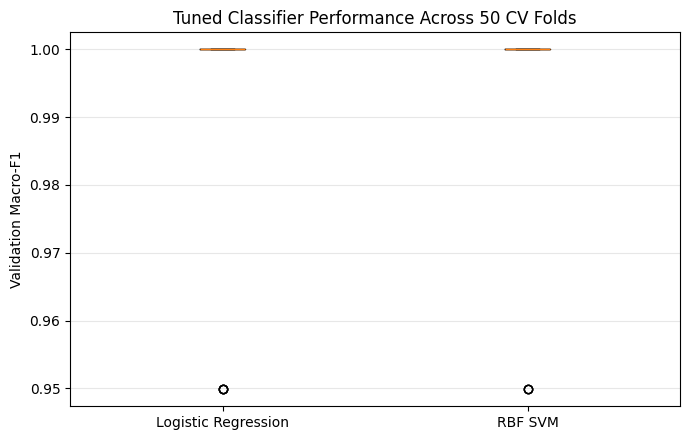

In [28]:
# Compare tuned Logistic Regression and RBF SVM

# Define the tuned models
final_models = {
    "Logistic Regression": lr_tuned_model,
    "RBF SVM": svm_tuned_model
}

# Store cross-validation results and fold-level Macro-F1 scores
comparison_rows = []
final_fold_scores = {}

# Evaluate both models using the same 50 CV splits
for model_name, model in final_models.items():

    results = cross_validate(
        model,
        X_train_scaled,
        y_train,
        cv=cv,
        scoring=svm_scoring,
        return_train_score=True,
        n_jobs=-1
    )

    # Save validation Macro-F1 scores for paired comparison
    final_fold_scores[model_name] = results["test_macro_f1"]

    # Calculate and store summary metrics
    comparison_rows.append({
        "Model": model_name,

        "Validation Accuracy":
            f"{results['test_accuracy'].mean():.4f} ± "
            f"{results['test_accuracy'].std():.4f}",

        "Validation Macro-F1":
            f"{results['test_macro_f1'].mean():.4f} ± "
            f"{results['test_macro_f1'].std():.4f}",

        "Balanced Accuracy":
            f"{results['test_balanced_accuracy'].mean():.4f} ± "
            f"{results['test_balanced_accuracy'].std():.4f}",

        "ROC-AUC":
            f"{results['test_roc_auc'].mean():.4f} ± "
            f"{results['test_roc_auc'].std():.4f}",

        "Train-CV Gap (Macro-F1)":
            round(
                results["train_macro_f1"].mean()
                - results["test_macro_f1"].mean(),
                4
            ),

        "Mean Fit Time (seconds)":
            round(results["fit_time"].mean(), 4)
    })


# Create the comparison table
comparison_df = pd.DataFrame(comparison_rows).set_index("Model")

# Add model complexity information
comparison_df["Model Complexity"] = [
    f"{np.count_nonzero(lr_tuned_model.coef_)} non-zero pixel weights",
    f"{svm_tuned_model.n_support_.sum()} support vectors"
]

print("Tuned Classifier Comparison")
print("Repeated Stratified 5-Fold CV × 10 Repeats")
print("Training data only (50 validation folds)\n")

show_table(comparison_df)


# Paired fold-by-fold Macro-F1 comparison
fold_differences = (
    final_fold_scores["RBF SVM"]
    - final_fold_scores["Logistic Regression"]
)

print("\nPaired Fold-by-Fold Comparison")
print("-" * 45)

print(
    f"Mean Macro-F1 difference (SVM - LR): "
    f"{fold_differences.mean():+.4f}"
)

print(
    f"RBF SVM performed better in: "
    f"{np.sum(fold_differences > 0)} folds"
)

print(
    f"Logistic Regression performed better in: "
    f"{np.sum(fold_differences < 0)} folds"
)

print(
    f"Both models tied in: "
    f"{np.sum(fold_differences == 0)} folds"
)


# Visualise the distribution of validation Macro-F1 scores
plt.figure(figsize=(7, 4.5))

plt.boxplot(
    [
        final_fold_scores["Logistic Regression"],
        final_fold_scores["RBF SVM"]
    ],
    tick_labels=["Logistic Regression", "RBF SVM"]
)

plt.ylabel("Validation Macro-F1")
plt.title("Tuned Classifier Performance Across 50 CV Folds")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


**Insight:**
- **The two tuned models perform equally well.** The RBF SVM (macro-F1 0.997 ± 0.012) and Logistic Regression (0.996 ± 0.014) differ by only 0.001, about one error per 1,000 validation predictions, which is far smaller than the fold-to-fold standard deviation.
- **The paired comparison confirms this.** Because both models were evaluated on identical folds, their scores can be compared fold by fold: they tied in 47 of 50 folds, with the SVM better in 2 and Logistic Regression better in 1. This split is consistent with chance, so neither model is meaningfully better.
- **Both generalise well.** Train–CV gaps are very small (0.003–0.004), so tuning removed any meaningful overfitting for both models.
- **Model complexity:** Logistic Regression uses 469 non-zero pixel weights. The remaining 315 pixels never contain ink in the training images, so their weights stay at zero (consistent with the zero-variance pixels found in Task 1). The SVM's decision boundary depends on only 27 of the 100 training images (its support vectors), which are the borderline digits closest to the boundary.

### Discussion: How the Two Models Differ and What the Results Show

| Aspect | Logistic Regression | RBF SVM |
|---|---|---|
| Decision boundary | Linear (a single straight hyperplane in pixel space) | Non-linear (can curve around unusual digits) |
| How it learns | Minimises log-loss over all training images | Maximises the margin, defined only by the support vectors |
| Output | Class probabilities | Decision scores (no calibrated probabilities) |
| Interpretability | High: each pixel weight can be shown as a 28×28 map | Low: no direct per-pixel explanation |
| Hyperparameter sensitivity | Robust: L2 scores ≥ 0.968 at every C tested | Sensitive: collapses to ~0.4 at large gamma |

**Connecting the differences to the results:**
- **The extra flexibility of the RBF kernel brought almost no benefit.** If the classes needed a curved boundary, the SVM would clearly outperform the linear model. Instead, both reach about 0.996–0.997. In addition, the SVM's best region (small gamma) is where its boundary is smoothest and closest to linear. This confirms the Task 1 finding that digits 1 and 7 are almost linearly separable in pixel space.
- **The models differ mainly in robustness, not accuracy.** Logistic Regression performs well across a very wide range of C, whereas the SVM only performs well within a narrow band of gamma and overfits badly outside it. The SVM therefore needs careful tuning to match a linear model.
- **Each model offers a different practical strength.** Logistic Regression is interpretable and produces probabilities. The SVM is compact, since its decision depends on only 27 training images.

**Conclusion:** both models are carried forward to the test set. Based on cross-validation alone they are statistically indistinguishable. Logistic Regression would be the practical choice because it is equally accurate, more robust to hyperparameter choice, and interpretable.

Final Evaluation on the Test Set

Both models were frozen before this step. The test set was not used for any training, tuning or model selection. It is used only once here, to report final performance on unseen data.

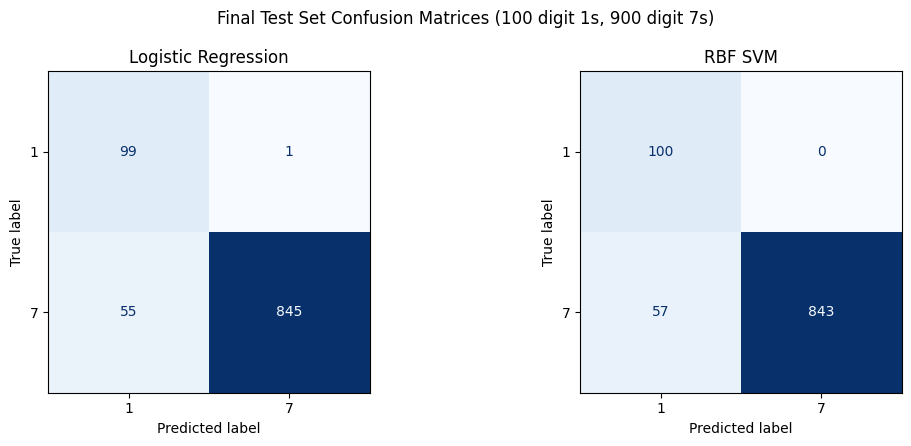

Final Test Set Performance
Frozen models | 1,000 unseen test images



,Accuracy,Macro-F1,Balanced Accuracy,ROC-AUC,Errors (of 1000)
Model,,,,,
Logistic Regression,0.944,0.8737,0.9644,0.9896,56
RBF SVM,0.943,0.8728,0.9683,0.9904,57


In [29]:

#  Final test set evaluation of frozen classifiers

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    ConfusionMatrixDisplay
)

# Store final test performance
test_comparison_rows = []

# Create confusion matrix plots
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Evaluate each frozen model on the test set
for ax, (model_name, model) in zip(axes, final_models.items()):

    # Generate predictions
    test_predictions = model.predict(X_test_scaled)

    # Obtain decision scores for ROC-AUC
    # Positive decision scores correspond to digit 7
    test_decision_scores = model.decision_function(X_test_scaled)

    # Calculate test performance metrics
    test_comparison_rows.append({
        "Model": model_name,

        "Accuracy": accuracy_score(
            y_test, test_predictions
        ),

        "Macro-F1": f1_score(
            y_test, test_predictions, average="macro"
        ),

        "Balanced Accuracy": balanced_accuracy_score(
            y_test, test_predictions
        ),

        "ROC-AUC": roc_auc_score(
            y_test, test_decision_scores
        ),

        "Errors (of 1000)": int(
            np.sum(test_predictions != y_test)
        )
    })

    # Display confusion matrix
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        test_predictions,
        labels=[1, 7],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")


# Display both confusion matrices
plt.suptitle(
    "Final Test Set Confusion Matrices (100 digit 1s, 900 digit 7s)"
)
plt.tight_layout()
plt.show()


# Create and display final test performance table
test_comparison_df = (
    pd.DataFrame(test_comparison_rows)
    .set_index("Model")
    .round(4)
)

print("Final Test Set Performance")
print("Frozen models | 1,000 unseen test images\n")

show_table(test_comparison_df)


**Insight:**
- **Test performance is lower than the cross-validation estimate** (macro-F1 about 0.87 vs 0.996 in CV). Both models make almost the same number of errors (56 vs 57), and almost all of them are **7s predicted as 1s**. The 1s are recognised almost perfectly.
- **Why:** (1) The 50 training 7s do not cover all the handwriting styles found among the 900 test 7s. Some test 7s have a short or faint top bar and look like 1s. (2) The models were trained on balanced 50/50 data, so their default threshold assumes both digits are equally common. In the test set, 90% of images are 7s, so borderline cases are labelled "1" too often.
- **The models still separate the digits well:** ROC-AUC remains about 0.99, so almost every 7 still scores higher than almost every 1. The errors come mainly from the position of the default decision threshold rather than from poor separation. Adjusting the threshold was not attempted, because it would require using the test set for decision-making.
- **This confirms the choice of metrics:** accuracy (0.944) is only slightly above the 0.90 achieved by always predicting "7", while macro-F1 (0.87) reveals the large number of false "1" predictions. Balanced accuracy (about 0.96) shows the models are still far better than chance on both classes.
- **Both models behave the same way**, which shows the limitation comes from the small training sample (100 images), not from the choice of classifier. The CV estimate was optimistic because it was based on only 100 balanced training images.